In [1]:
import pandas as pd
# Install spacy
## -q is for "quiet". It removes logs
%pip install spacy -q
# Import spacy, if you don't have it --> !pip install spacy
import spacy
spacy.__version__
# Download model
!python -m spacy download en_core_web_sm -q
# Import english stop words
from spacy.lang.en.stop_words import STOP_WORDS
import re

Note: you may need to restart the kernel to use updated packages.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
data = pd.read_csv(r'C:\Users\LN\Documents\Jedha\Projets\NORTH_FACE\Helene\data\sample_clean.csv')

In [3]:
data.head()

,id,products,advantages,description_text,details,fabric,weight,country
0,1,active classic boxers,there's a reason why our boxers are a cult fav...,active classic boxers - there s a reason why o...,"silky capilene 1 fabric is ultralight, breatha...",3.7-oz 100% all-recycled polyester with gladio...,99 g 3.5 oz,mexico
1,2,active sport boxer briefs,skinning up glory requires enough movement wit...,active sport boxer briefs - skinning up glory ...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",60 g 2.1 oz,israel
2,3,active sport briefs,these superbreathable no-fly briefs are the mi...,active sport briefs - these superbreathable no...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",49 g 1.7 oz,israel
3,4,alpine guide pants,"skin in, climb ice, switch to rock, traverse a...","alpine guide pants - skin in, climb ice, switc...",durable stretch-woven polyester 47% recycled w...,7.6-oz 90-denier 92% polyester 47% recycled /8...,597 g 20.7 oz,vietnam
4,5,alpine wind jkt,"on high ridges, steep ice and anything alpine,...","alpine wind jkt - on high ridges, steep ice an...","lightweight, breathable polyester ripstop fabr...",shell 1.3-oz 20-denier 100% polyester ripstop....,331 g 11.5 oz,china


In [4]:
type(data)

pandas.core.frame.DataFrame

In [5]:
data['products'].tolist()

['active classic boxers',
 'active sport boxer briefs',
 'active sport briefs',
 'alpine guide pants',
 'alpine wind jkt',
 'ascensionist jkt',
 'atom',
 'print banded betina btm',
 'baby micro d-luxe cardigan',
 'baby sun bucket hat',
 'baby sunshade top',
 'baggies shorts',
 'beach bucket',
 'better sweater jkt',
 'borderless shorts-11 in.',
 'borderless shorts-7 in.',
 'bucket hat',
 'cap 1 bottoms',
 'cap 1 boxer briefs',
 'cap 1 graphic t-shirt',
 'cap 1 t-shirt',
 'cap 2 t-shirt',
 'cap 2 zip neck',
 'cap 3 zip neck',
 'cap 4 bottoms',
 'city by the sea t-shirt',
 'compound cargo pants',
 'compound cargo pants',
 'continental shorts',
 'cotton board shorts',
 'crosstown',
 'custodian pants',
 'deep wading jkt',
 'delivery shorts',
 'down sweater vest',
 'dragoons t-shirt',
 'duck pants',
 'elias fz sweatshirt',
 'elias sweatshirt',
 'fezzman shirt',
 'fish frenzy t-shirt',
 'freewheeler',
 'gi ii pants',
 'gi ii shorts',
 "girl's boardie capris",
 "girl's boardie shorts",
 "girl'

In [6]:
cols = ["products", 'advantages', 'details', 'fabric', 'weight', 'country', 'description_text']
[data[c].str.lower() for c in cols]

[0          active classic boxers
 1      active sport boxer briefs
 2            active sport briefs
 3             alpine guide pants
 4                alpine wind jkt
                  ...            
 495                cap 2 bottoms
 496                   cap 2 crew
 497               all-time shell
 498        all-wear cargo shorts
 499              all-wear shorts
 Name: products, Length: 500, dtype: object,
 0      there's a reason why our boxers are a cult fav...
 1      skinning up glory requires enough movement wit...
 2      these superbreathable no-fly briefs are the mi...
 3      skin in, climb ice, switch to rock, traverse a...
 4      on high ridges, steep ice and anything alpine,...
                              ...                        
 495    cut loose from the maddening crowds and search...
 496    this crew takes the edge off fickle weather. i...
 497    no need to use that morning times as an umbrel...
 498    all-wear cargo shorts bask in the glory of swe...
 

In [7]:
data['text'] = data['products'] + ' ' + data['advantages']

In [8]:
keywords = [
    'bag',
    'baggage',
    'belt',
    'boot',
    'bottom',
    'boxer',
    'bra',
    'brief',
    'bucket',
    'cap',
    'capri',
    'cardigan',
    'divider',
    'dress',
    'duffle',
    'floor mat'
    'hat',
    'jeans-'
    'jkt', 
    'p/o',
    'pant',
    'polo',
    'poster',
    'rashguard',
    'shirt',
    'short',
    'skirt',
    'sneaker',
    'sock',
    'storage locker',
    'sweater',
    'tank',
    'top',
    'tote',
    't-shir',
    't-shirt',
    'trunk',
    'underwear',
    'vest',
    'wader',
    'zip neck'
    ]
treatment = [re.escape(word.strip()) for word in keywords if word.strip()]
pattern = r"(?<!\w)(?:" + "|".join(treatment) + r")(?!\w)" if treatment else r"(?!)"
find = data["advantages"].str.contains(pattern, case=False, na=False)
not_found = data.loc[~find, ["id", "products", "advantages"]]
print(f"{len(not_found)} documents sans mot-clé sur {len(data)}")
not_found

213 documents sans mot-clé sur 500


,id,products,advantages
2,3,active sport briefs,these superbreathable no-fly briefs are the mi...
3,4,alpine guide pants,"skin in, climb ice, switch to rock, traverse a..."
4,5,alpine wind jkt,"on high ridges, steep ice and anything alpine,..."
5,6,ascensionist jkt,our most technical soft shell for full-on moun...
7,8,print banded betina btm,"our fullest coverage bottoms, the betina fits ..."
...,...,...,...
494,495,active briefs,"these featherweight, quick-wicking briefs keep..."
495,496,cap 2 bottoms,cut loose from the maddening crowds and search...
496,497,cap 2 crew,this crew takes the edge off fickle weather. i...
497,498,all-time shell,no need to use that morning times as an umbrel...


In [9]:
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,there's a reason why our boxers are a cult fav...,active classic boxers - there s a reason why o...,"silky capilene 1 fabric is ultralight, breatha...",3.7-oz 100% all-recycled polyester with gladio...,99 g 3.5 oz,mexico,active classic boxers there's a reason why our...


In [10]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['text'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

# # Ajouter des stop words personnalisés
# nlp.Defaults.stop_words.update({"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"})

# # Appliquer les modifications au vocabulaire
# for word in {"and", "the", "a", "for", "in", "to", "of", "is", "on", "from"}:
#     nlp.vocab[word].is_stop = True

Tokens: ['active', 'classic', 'boxers', 'there', "'s", 'a', 'reason', 'why', 'our', 'boxers', 'are', 'a', 'cult', 'favorite', '-', 'they', 'keep', 'their', 'cool', ',', 'especially', 'in', 'sticky', 'situations', '.', 'the', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'up', 'minimal', 'space', 'in', 'a', 'travel', 'pack', '.', 'an', 'exposed', ',', 'brushed', 'waistband', 'offers', 'next', '-', 'to', '-', 'skin', 'softness', ',', 'five', '-', 'panel', 'construction', 'with', 'a', 'traditional', 'boxer', 'back', 'for', 'a', 'classic', 'fit', ',', 'and', 'a', 'functional', 'fly', '.', 'made', 'of', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'with', 'moisture', '-', 'wicking', 'performance', '.', 'inseam', '(', 'size', 'm', ')', 'is', '4', '1/2', '"', '.', 'recyclable', 'through', 'the', 'common', 'threads', 'recycling', 'program', '.']
------------
Lemma: ['active', 'classic', 'boxer', 'there', 'be', 'a', 'reason', 'why', 'our', 'boxer', 'be', 'a', 'cult

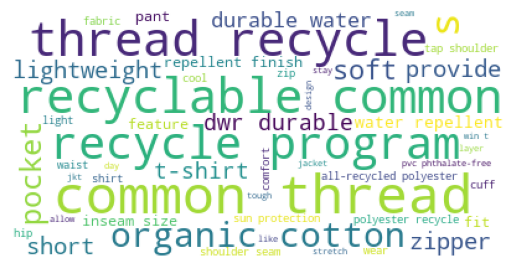

In [11]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud
from spacy.lang.en.stop_words import STOP_WORDS
from spacy.lang.char_classes import HYPHENS
from spacy.util import compile_infix_regex

infixes = [x for x in nlp.Defaults.infixes if HYPHENS not in x]
nlp.tokenizer.infix_finditer = compile_infix_regex(infixes).finditer

text = " ".join(data['text'].astype(str))
text = re.sub(r"<[^>]+>", " ", text) # replace html
# Garder uniquement les lettres anglaises, espaces et tirets
text = re.sub(r"[^a-z\s-]+", " ", text.lower())

# Garder uniquement les tirets entre deux lettres
text = re.sub(r"(?<![a-z])-|-(?![a-z])", " ", text)

# Normaliser les espaces
text = re.sub(r"\s+", " ", text).strip()

doc = nlp(text)
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]
lemma

cloud = wordcloud.WordCloud(
    regexp=r"[\w'-]+", # MODIF : garde les mots avec tiret
    stopwords=STOP_WORDS, 
    collocations=True, # remove bigrams
    min_font_size=7,
    background_color="white", 
    colormap="viridis"
).generate(" ".join(lemma)) # remove stopwords

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

In [12]:
data.head()

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,there's a reason why our boxers are a cult fav...,active classic boxers - there s a reason why o...,"silky capilene 1 fabric is ultralight, breatha...",3.7-oz 100% all-recycled polyester with gladio...,99 g 3.5 oz,mexico,active classic boxers there's a reason why our...
1,2,active sport boxer briefs,skinning up glory requires enough movement wit...,active sport boxer briefs - skinning up glory ...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",60 g 2.1 oz,israel,active sport boxer briefs skinning up glory re...
2,3,active sport briefs,these superbreathable no-fly briefs are the mi...,active sport briefs - these superbreathable no...,"stretch mesh provides support, open-weave mesh...","4.6-oz 93% polyester 71% recycled /7% spandex,...",49 g 1.7 oz,israel,active sport briefs these superbreathable no-f...
3,4,alpine guide pants,"skin in, climb ice, switch to rock, traverse a...","alpine guide pants - skin in, climb ice, switc...",durable stretch-woven polyester 47% recycled w...,7.6-oz 90-denier 92% polyester 47% recycled /8...,597 g 20.7 oz,vietnam,"alpine guide pants skin in, climb ice, switch ..."
4,5,alpine wind jkt,"on high ridges, steep ice and anything alpine,...","alpine wind jkt - on high ridges, steep ice an...","lightweight, breathable polyester ripstop fabr...",shell 1.3-oz 20-denier 100% polyester ripstop....,331 g 11.5 oz,china,"alpine wind jkt on high ridges, steep ice and ..."


In [13]:
from collections import Counter; Counter(lemma).most_common()

[('recycle', 413),
 ('pocket', 361),
 ('recyclable', 332),
 ('thread', 331),
 ('common', 329),
 ('program', 328),
 ('s', 313),
 ('polyester', 247),
 ('organic', 190),
 ('fabric', 189),
 ('cotton', 178),
 ('soft', 157),
 ('short', 151),
 ('durable', 149),
 ('zipper', 144),
 ('water', 141),
 ('dry', 140),
 ('nylon', 140),
 ('fit', 132),
 ('lightweight', 129),
 ('t-shirt', 128),
 ('spandex', 121),
 ('oz', 120),
 ('feature', 120),
 ('seam', 120),
 ('pant', 117),
 ('provide', 116),
 ('shoulder', 110),
 ('inseam', 104),
 ('breathable', 104),
 ('finish', 103),
 ('blend', 99),
 ('shirt', 95),
 ('dwr', 92),
 ('strap', 91),
 ('sun', 90),
 ('repellent', 89),
 ('hem', 89),
 ('size', 86),
 ('layer', 84),
 ('merino', 83),
 ('comfort', 82),
 ('protection', 81),
 ('neck', 78),
 ('fly', 77),
 ('stretch', 75),
 ('light', 75),
 ('sleeve', 74),
 ('cuff', 73),
 ('skin', 72),
 ('t', 72),
 ('include', 72),
 ('long', 72),
 ('all-recycled', 68),
 ('cool', 66),
 ('pack', 66),
 ('waistband', 65),
 ('waist', 65),

La taille d’un mot dépend de sa fréquence dans le texte : plus il est gros, plus il apparaît souvent. La position, l’orientation et la couleur sont aléatoires et n’ont aucune signification. dwr signifie Durable Water Repellent. g pourrait mesurer le poids. 

Prochaines étapes 
data mining avec tf idf
retirer le bruit

In [14]:
# # import displacy
# from spacy import displacy

# # render displacy
# sample = nlp(data['description'].astype(str).iloc[0])
# displacy.render(list(sample.sents)[0], style='dep', jupyter=True,options={'distance': 70})

# text mining

## create an array of odcuments

In [15]:
# type(lemma)

In [16]:
# import pandas as pd
# series = pd.Series(lemma)

In [17]:
# series = pd.Series([" ".join(token.lemma_ for token in d if token.lemma_ not in STOP_WORDS) for d in docs])
# df = pd.DataFrame(series, columns=["text"])

In [18]:
# df.value_counts() > 50

In [19]:
# type(df)

In [20]:
# df.head()

In [21]:
# # Tfidf transformer
# from sklearn.feature_extraction.text import TfidfVectorizer

# # TF-IDF vector
# vectorizer = TfidfVectorizer()
# X = vectorizer.fit_transform(df['text'])

# # X is a generator. We can transform that as an array
# dense = X.toarray()
# dense


In [22]:
# # Creating a DataFrame with all the words and tf-idf score
# tfid_df = pd.DataFrame(dense,
#                         columns=[x for x in vectorizer.get_feature_names_out()])

# tfid_df

In [23]:
# # Transpose dataframe
# tfid_df = tfid_df.T

# # Create a new token column
# tfid_df["token"] = tfid_df.index

# tfid_df

In [24]:
# # Sort the top 15 values by descending order
# tfid_df.sort_values(by=0, ascending=False)[:15]

In [25]:
# # Import plotly express
# import plotly.express as px
# for i in tfid_df.columns.drop("token"):
#     top = tfid_df.sort_values(by=i, ascending=False)[:15]
#     print(i, list(top["token"]))

# # Create bar chart
# fig = px.bar(tfid_df.sort_values(by=0, ascending=False)[:15].reset_index(), x="token", y=0)

# # Render chart
# fig.show()

In [26]:
# clothes = ["boxer", "brief", "pant", "jkt", "short", "shorts", "hat", "cap", "shirt", "sweater", "cardigan"]

# for i in tfid_df.columns.drop("token"):
#     top = tfid_df[tfid_df[i] > 0].sort_values(by=i, ascending=False)[:15]
#     found = [t for t in top["token"] if t in clothes]
#     print(i, found)

In [27]:
pd.set_option("display.max_rows", None)      # show all rows
pd.set_option("display.max_colwidth", None)  # no column truncation

In [28]:
data[["products", "advantages"]].drop_duplicates(subset="products")
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxers - there s a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam size m is 4 1/2 . recyclable through the common threads recycling program.","silky capilene 1 fabric is ultralight, breathable and quick-to-dry exposed, brushed elastic waistband for comfort 5-panel construction with traditional boxer back inseam size m is 4 1/2",3.7-oz 100% all-recycled polyester with gladiodor natural odor control for the garment. recyclable through the common threads recycling program,99 g 3.5 oz,mexico,"active classic boxers there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program."


In [29]:
data['text'] = data['products'] + ' ' + data['advantages']

In [30]:
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text
0,1,active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxers - there s a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam size m is 4 1/2 . recyclable through the common threads recycling program.","silky capilene 1 fabric is ultralight, breathable and quick-to-dry exposed, brushed elastic waistband for comfort 5-panel construction with traditional boxer back inseam size m is 4 1/2",3.7-oz 100% all-recycled polyester with gladiodor natural odor control for the garment. recyclable through the common threads recycling program,99 g 3.5 oz,mexico,"active classic boxers there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program."


In [31]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['text'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))


Tokens: ['active', 'classic', 'boxers', 'there', "'s", 'a', 'reason', 'why', 'our', 'boxers', 'are', 'a', 'cult', 'favorite', '-', 'they', 'keep', 'their', 'cool', ',', 'especially', 'in', 'sticky', 'situations', '.', 'the', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'up', 'minimal', 'space', 'in', 'a', 'travel', 'pack', '.', 'an', 'exposed', ',', 'brushed', 'waistband', 'offers', 'next', '-', 'to', '-', 'skin', 'softness', ',', 'five', '-', 'panel', 'construction', 'with', 'a', 'traditional', 'boxer', 'back', 'for', 'a', 'classic', 'fit', ',', 'and', 'a', 'functional', 'fly', '.', 'made', 'of', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'with', 'moisture', '-', 'wicking', 'performance', '.', 'inseam', '(', 'size', 'm', ')', 'is', '4', '1/2', '"', '.', 'recyclable', 'through', 'the', 'common', 'threads', 'recycling', 'program', '.']
------------
Lemma: ['active', 'classic', 'boxer', 'there', 'be', 'a', 'reason', 'why', 'our', 'boxer', 'be', 'a', 'cult

In [43]:
def lemma(doc):
    return "".join(token.lemma_ + token.whitespace_ for token in doc).strip()

keywords = [
    'bag',
    'baggage',
    'belt',
    'boot',
    'bottom',
    'boxer',
    'bra',
    'brief',
    'bucket',
    'cap',
    'capri',
    'cardigan',
    'divider',
    'dress',
    'duffle',
    'floor mat'
    'hat',
    'jeans-'
    'jacket', 
    'p/o',
    'pant',
    'polo',
    'poster',
    'rashguard',
    'shirt',
    'short',
    'skirt',
    'sneaker',
    'sock',
    'storage locker',
    'sweater',
    'tank',
    'top',
    'tote',
    't-shir',
    't-shirt',
    'trunk',
    'underwear',
    'vest',
    'wader',
    'zip neck'
    ]
data["lemma"] = [lemma(doc) for doc in docs]
keywords_lemma = [lemma(doc) for doc in nlp.pipe(keywords)]
treatment = [re.escape(word) for word in keywords_lemma if word]
pattern = r"(?<!\w)(?:" + "|".join(treatment) + r")(?!\w)" if treatment else r"(?!)"
search = data["lemma"].str.contains(pattern, case=False, na=False)
not_found = data.loc[~search, ["lemma", "products", "advantages"]]
print(f"{len(not_found)} documents sans mot-clé sur {len(data)}")
not_found.head(1)

82 documents sans mot-clé sur 500


,lemma,products,advantages
4,"alpine wind jkt on high ridge, steep ice and anything alpine, this jacket serve as a true ""good of all world"" staple. it excel as a stand-alone shell for blustery rock climb, cool-weather trail run and high-output ski tour. and then, when condition have you ice and alpine climbing, it function as a lightly insulate windshirt on the approach, as well as a frictionless midlayer when itbe time to bundle up and tie-in. the polyester ripstop shell with a deluge dwr (durable water repellent) treatment shed snow and block wind, while the smooth, lightly brush hang mesh liner wick moisture, dry fast, and donot bind to your baselayer. superlight stretch-weave underarm panel enhance breathability and allow for unimpaired arm motion, and the two hand pocket close with zipper. a drawcord hem, elastic cuff, a heat-transfer reflective logo and a regular-coil, center-front zipper with dwr finish round out the feature. update this season for an improve fit. recyclable through the common thread recycle program.",alpine wind jkt,"on high ridges, steep ice and anything alpine, this jacket serves as a true ""best of all worlds"" staple. it excels as a stand-alone shell for blustery rock climbs, cool-weather trail runs and high-output ski tours. and then, when conditions have you ice and alpine climbing, it functions as a lightly insulated windshirt on the approach, as well as a frictionless midlayer when it's time to bundle up and tie-in. the polyester ripstop shell with a deluge dwr (durable water repellent) treatment sheds snow and blocks wind, while the smooth, lightly brushed hanging mesh liner wicks moisture, dries fast, and doesn't bind to your baselayers. superlight stretch-woven underarm panels enhance breathability and allow for unimpaired arm motion, and the two hand pockets close with zippers. a drawcord hem, elastic cuffs, a heat-transfer reflective logo and a regular-coil, center-front zipper with dwr finish round out the features. updated this season for an improved fit. recyclable through the common threads recycling program."


In [45]:
line = data["products"].eq("alpine wind jacket")
print("Lemme de jkt :", repr(lemma(nlp("jacket"))))
print("Motif reconnaît jacket :", bool(re.search(pattern, "jacket", re.I)))
print("Produit détecté :", search.loc[line].tolist())

Lemme de jkt : 'jacket'
Motif reconnaît jacket : False
Produit détecté : []


In [46]:
data.head(1)

,id,products,advantages,description_text,details,fabric,weight,country,text,lemma
0,1,active classic boxers,"there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxers - there s a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam size m is 4 1/2 . recyclable through the common threads recycling program.","silky capilene 1 fabric is ultralight, breathable and quick-to-dry exposed, brushed elastic waistband for comfort 5-panel construction with traditional boxer back inseam size m is 4 1/2",3.7-oz 100% all-recycled polyester with gladiodor natural odor control for the garment. recyclable through the common threads recycling program,99 g 3.5 oz,mexico,"active classic boxers there's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. the quick-drying, lightweight underwear takes up minimal space in a travel pack. an exposed, brushed waistband offers next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. made of 3.7-oz 100% recycled polyester with moisture-wicking performance. inseam (size m) is 4 1/2"". recyclable through the common threads recycling program.","active classic boxer therebe a reason why our boxer be a cult favorite - they keep their cool, especially in sticky situation. the quick-dry, lightweight underwear take up minimal space in a travel pack. an expose, brush waistband offer next-to-skin softness, five-panel construction with a traditional boxer back for a classic fit, and a functional fly. make of 3.7-oz 100% recycled polyester with moisture-wicke performance. inseam (size m) be 4 1/2"". recyclable through the common thread recycle program."


In [35]:
# import re
# # Import matplotlib and wordcloud
# import matplotlib.pyplot as plt
# import wordcloud
# from spacy.lang.en.stop_words import STOP_WORDS
# from spacy.lang.char_classes import HYPHENS
# from spacy.util import compile_infix_regex

# infixes = [x for x in nlp.Defaults.infixes if HYPHENS not in x]
# nlp.tokenizer.infix_finditer = compile_infix_regex(infixes).finditer

# text = " ".join(data['text'].astype(str))
# text = re.sub(r"<[^>]+>", " ", text) # replace html
# # Garder uniquement les lettres anglaises, espaces et tirets
# text = re.sub(r"[^a-z\s-]+", " ", text.lower())

# # Garder uniquement les tirets entre deux lettres
# text = re.sub(r"(?<![a-z])-|-(?![a-z])", " ", text)

# # Normaliser les espaces
# text = re.sub(r"\s+", " ", text).strip()

# doc = nlp(text)
# lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]
# lemma

# cloud = wordcloud.WordCloud(
#     regexp=r"[\w'-]+", # MODIF : garde les mots avec tiret
#     stopwords=STOP_WORDS, 
#     collocations=True, # keep bigrams
#     min_font_size=7,
#     background_color="white", 
#     colormap="viridis"
# ).generate(" ".join(lemma)) # remove stopwords

# # Show word cloud with matplotlib
# plt.imshow(cloud)
# plt.axis("off")

# # Remove trailing logs
# plt.show()

In [36]:
# keywords = [
#     'bag',
#     'baggage',
#     'belt',
#     'boot',
#     'bottom',
#     'boxer',
#     'bra',
#     'brief',
#     'bucket',
#     'cap',
#     'capri',
#     'cardigan',
#     'divider',
#     'dress',
#     'duffle',
#     'floor mat'
#     'hat',
#     'jeans-'
#     'jkt', 
#     'p/o',
#     'pant',
#     'polo',
#     'poster',
#     'rashguard',
#     'shirt',
#     'short',
#     'skirt',
#     'sneaker',
#     'sock',
#     'storage locker',
#     'sweater',
#     'tank',
#     'top',
#     'tote',
#     't-shir',
#     't-shirt',
#     'trunk',
#     'underwear',
#     'vest',
#     'wader',
#     'zip neck'
#     ]
# treatment = [re.escape(word.strip()) for word in keywords if word.strip()]
# pattern = r"(?<!\w)(?:" + "|".join(treatment) + r")(?!\w)" if treatment else r"(?!)"
# find = lemma.str.contains(pattern, case=False, na=False)
# not_found = data.loc[~find, lemma]
# print(f"{len(not_found)} documents sans mot-clé sur {len(data)}")
# not_found

In [37]:
# # text mining
# ## create an array of odcuments
# type(lemma)
# import pandas as pd
# series = pd.Series(lemma)
# series = pd.Series([" ".join(token.lemma_ for token in d if token.lemma_ not in STOP_WORDS) for d in docs])
# data = pd.DataFrame(series, columns=["text"])
# data.value_counts() > 50
# type(data)
# data.head()
# # Tfidf transformer
# from sklearn.feature_extraction.text import TfidfVectorizer

# # TF-IDF vector
# vectorizer = TfidfVectorizer()
# X = vectorizer.fit_transform(data['text'])

# # X is a generator. We can transform that as an array
# dense = X.toarray()
# dense

# # Creating a DataFrame with all the words and tf-idf score
# tfid_df = pd.DataFrame(dense,
#                         columns=[x for x in vectorizer.get_feature_names_out()])

# tfid_df
# # Transpose dataframe
# tfid_df = tfid_df.T

# # Create a new token column
# tfid_df["token"] = tfid_df.index

# tfid_df
# # Sort the top 15 values by descending order
# tfid_df.sort_values(by=0, ascending=False)[:15]
# # Import plotly express
# import plotly.express as px
# for i in tfid_df.columns.drop("token"):
#     top = tfid_df.sort_values(by=i, ascending=False)[:15]
#     print(i, list(top["token"]))

# # Create bar chart
# fig = px.bar(tfid_df.sort_values(by=0, ascending=False)[:15].reset_index(), x="token", y=0)

# # Render chart
# fig.show()